**Abri Arquivo**

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

arquivo = Path("dados/processed/enem_2023_lc_c07.parquet")
if not arquivo.exists():
    raise FileNotFoundError(
        f"Base não encontrada: {arquivo.resolve()}\n"
        "Gere-a na raiz do projeto com: "
        "python -m src.conjuntos.exportar_conjunto C07"
    )

df = pd.read_parquet(arquivo)

print("Arquivo:", arquivo.resolve())
print("Dimensões:", df.shape)
display(df.head())


**Preparar os dados**

In [ ]:
# Usar somente o conjunto de desenvolvimento durante a preparação e validação
dev = df.loc[df["CONJUNTO"] == "desenvolvimento"].reset_index(drop=True)
teste = df.loc[df["CONJUNTO"] == "teste"].reset_index(drop=True)

X = dev.drop(columns=["NU_INSCRICAO", "CONJUNTO", "DOBRA", "NU_NOTA_LC"])
y = dev["NU_NOTA_LC"]

print("Desenvolvimento:", X.shape, "— dobras:", sorted(dev["DOBRA"].unique()))
print("Teste reservado para avaliação final:", teste.shape)

Desenvolvimento: (2258114, 23) — dobras: [np.int8(1), np.int8(2), np.int8(3)]
Teste reservado para avaliação final: (564529, 27)


**Separar treino e teste**

In [ ]:
# As dobras oficiais (DOBRA 1, 2 e 3) pertencem somente ao desenvolvimento
import numpy as np

dobras = [(
    np.flatnonzero(dev["DOBRA"].to_numpy() != k),
    np.flatnonzero(dev["DOBRA"].to_numpy() == k)
) for k in (1, 2, 3)]

# O teste fica separado e não participa da validação cruzada
X_teste = teste.drop(columns=["NU_INSCRICAO", "CONJUNTO", "DOBRA", "NU_NOTA_LC"])
y_teste = teste["NU_NOTA_LC"]
print("Dobras:", [len(validacao) for _, validacao in dobras])

Dobras: [752705, 752705, 752704]


**Preparar as categorias e os valores ausentes**

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
ordens={"Q006":list("ABCDEFGHIJKLMNOPQ"),"Q001":list("ABCDEFGH"),"Q002":list("ABCDEFGH"),"Q003":list("ABCDEF"),"Q004":list("ABCDEF"),"Q024":list("ABCDE"),"Q025":list("AB"),"ESCOLARIDADE_MAX_RESP":list("ABCDEFG")+["INDETERMINADA"],"TP_FAIXA_ETARIA":[str(i) for i in range(1,21)]}
ord=[c for c in ordens if c in X.columns]; cat=[c for c in X.select_dtypes(include=["object","category"]).columns if c not in ord]; num=[c for c in X.columns if c not in ord+cat]
steps=[]
if ord: steps.append(("ord",OrdinalEncoder(categories=[ordens[c] for c in ord],handle_unknown="use_encoded_value",unknown_value=-1),ord))
if cat: steps.append(("cat",OrdinalEncoder(handle_unknown="use_encoded_value",unknown_value=-1),cat))
if num: steps.append(("num",SimpleImputer(strategy="median",add_indicator=True),num))
modelo_arvore=Pipeline([("preprocessamento",ColumnTransformer(steps)),("modelo",DecisionTreeRegressor(random_state=42))])

**Treinar a Árvore de Decisão**

In [ ]:
import time
inicio = time.time()
modelo_arvore.fit(X, y)
tempo_arvore = time.time() - inicio
print(f"Treinamento concluído em {tempo_arvore:.1f} segundos!")

Treinamento concluído em 47.7 segundos!


Validação cruzada oficial (3 dobras)

In [ ]:
from sklearn.model_selection import cross_validate
import time

inicio_cv = time.time()
resultados_cv = cross_validate(
    modelo_arvore, X, y, cv=dobras,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2",
    },
    n_jobs=1,
)
tempo_cv = time.time() - inicio_cv
print("RESULTADOS — VALIDAÇÃO CRUZADA OFICIAL (3 DOBRAS)")
print(f"MAE médio:  {-resultados_cv['test_MAE'].mean():.2f}")
print(f"RMSE médio: {-resultados_cv['test_RMSE'].mean():.2f}")
print(f"R² médio:    {resultados_cv['test_R2'].mean():.4f}")
print(f"Tempo:       {tempo_cv / 60:.2f} minutos")

RESULTADOS — VALIDAÇÃO CRUZADA OFICIAL (3 DOBRAS)
MAE médio:  71.27
RMSE médio: 92.48
R² médio:    -0.5012
Tempo:       1.85 minutos


In [ ]:
from sklearn.base import clone
from sklearn.ensemble import StackingRegressor
from sklearn.linear_model import Ridge
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
import time

preprocessador_base = modelo_arvore.named_steps["preprocessamento"]
modelo_arvore_stack = Pipeline([
    ("preprocessamento", clone(preprocessador_base)),
    ("modelo", DecisionTreeRegressor(
        max_depth=8, min_samples_leaf=100, random_state=42
    )),
])
modelo_ridge_stack = Pipeline([
    ("preprocessamento", clone(preprocessador_base)),
    ("modelo", Ridge(alpha=10.0)),
])
modelo_stacking = StackingRegressor(
    estimators=[("arvore", modelo_arvore_stack), ("ridge", modelo_ridge_stack)],
    final_estimator=Ridge(alpha=1.0),
    cv=3,
    n_jobs=1,
)

inicio_cv_stacking = time.time()
resultados_cv_stacking = cross_validate(
    modelo_stacking, X, y, cv=dobras,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2",
    },
    n_jobs=1,
)
tempo_cv_stacking = time.time() - inicio_cv_stacking

print("RESULTADOS — STACKING, VALIDAÇÃO CRUZADA OFICIAL (3 DOBRAS)")
print(f"MAE médio:  {-resultados_cv_stacking['test_MAE'].mean():.2f}")
print(f"RMSE médio: {-resultados_cv_stacking['test_RMSE'].mean():.2f}")
print(f"R² médio:    {resultados_cv_stacking['test_R2'].mean():.4f}")
print(f"Tempo:       {tempo_cv_stacking / 60:.2f} minutos")

RESULTADOS — STACKING, VALIDAÇÃO CRUZADA OFICIAL (3 DOBRAS)
MAE médio:  50.75
RMSE médio: 65.81
R² médio:    0.2399
Tempo:       4.75 minutos


Avaliação final no conjunto de teste

In [ ]:
import time
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

inicio_final = time.time()
modelo_arvore.fit(X, y)  # ajuste final em todo o conjunto de desenvolvimento
tempo_final = time.time() - inicio_final

previsoes_teste = modelo_arvore.predict(X_teste)
mae_teste = mean_absolute_error(y_teste, previsoes_teste)
rmse_teste = np.sqrt(mean_squared_error(y_teste, previsoes_teste))
r2_teste = r2_score(y_teste, previsoes_teste)

print("RESULTADOS FINAIS — TESTE RESERVADO")
print(f"MAE:  {mae_teste:.2f}")
print(f"RMSE: {rmse_teste:.2f}")
print(f"R²:   {r2_teste:.4f}")
print(f"Tempo de ajuste em desenvolvimento: {tempo_final / 60:.2f} minutos")

RESULTADOS FINAIS — TESTE RESERVADO
MAE:  70.30
RMSE: 91.34
R²:   -0.4702
Tempo de ajuste em desenvolvimento: 0.79 minutos


In [ ]:
inicio_final_stacking = time.time()
modelo_stacking.fit(X, y)  # ajuste final em todo o conjunto de desenvolvimento
tempo_final_stacking = time.time() - inicio_final_stacking

previsoes_stacking_teste = modelo_stacking.predict(X_teste)
mae_stacking_teste = mean_absolute_error(y_teste, previsoes_stacking_teste)
rmse_stacking_teste = np.sqrt(mean_squared_error(y_teste, previsoes_stacking_teste))
r2_stacking_teste = r2_score(y_teste, previsoes_stacking_teste)

print("RESULTADOS FINAIS — STACKING NO TESTE RESERVADO")
print(f"MAE:  {mae_stacking_teste:.2f}")
print(f"RMSE: {rmse_stacking_teste:.2f}")
print(f"R²:   {r2_stacking_teste:.4f}")
print(f"Tempo de ajuste em desenvolvimento: {tempo_final_stacking / 60:.2f} minutos")

RESULTADOS FINAIS — STACKING NO TESTE RESERVADO
MAE:  50.67
RMSE: 65.73
R²:   0.2387
Tempo de ajuste em desenvolvimento: 2.21 minutos


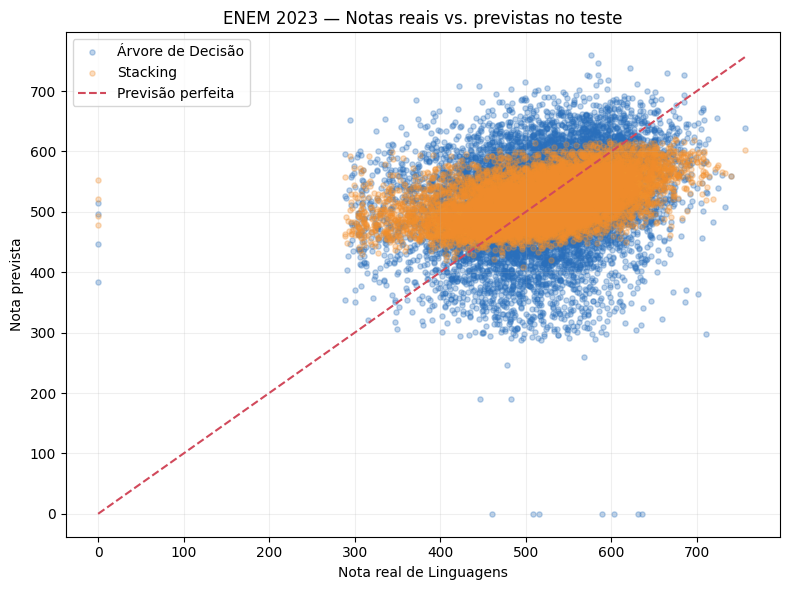

In [ ]:
import matplotlib.pyplot as plt

# Mesma amostra do teste para comparar os dois modelos
rng = np.random.default_rng(42)
indices = rng.choice(len(y_teste), size=min(10000, len(y_teste)), replace=False)
notas_reais = np.asarray(y_teste)[indices]
notas_previstas_arvore = previsoes_teste[indices]
notas_previstas_stacking = previsoes_stacking_teste[indices]

limite_min = min(notas_reais.min(), notas_previstas_arvore.min(), notas_previstas_stacking.min())
limite_max = max(notas_reais.max(), notas_previstas_arvore.max(), notas_previstas_stacking.max())

plt.figure(figsize=(8, 6))
plt.scatter(notas_reais, notas_previstas_arvore, alpha=0.30, s=14, color="#2a6fbb", label="Árvore de Decisão")
plt.scatter(notas_reais, notas_previstas_stacking, alpha=0.30, s=14, color="#f28e2b", label="Stacking")
plt.plot([limite_min, limite_max], [limite_min, limite_max], "--", color="#d1495b", label="Previsão perfeita")
plt.xlabel("Nota real de Linguagens")
plt.ylabel("Nota prevista")
plt.title("ENEM 2023 — Notas reais vs. previstas no teste")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()